In [ ]:
import tensorflow as tf
import matplotlib.pyplot as pt
from sklearn import datasets
import pandas as pd
import numpy as np
from tensorflow.keras.layers import Flatten

In [ ]:
# !pip install huggingface_hub

In [ ]:
# from datasets import load_dataset

# ds = load_dataset("moonworks/lunara-art-eval")

In [ ]:
# from dotenv import load_dotenv
# load_dotenv()

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()


In [ ]:
np.unique(y_train)

In [ ]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)


In [ ]:
X_train[0].shape

In [ ]:
pt.imshow(X_train[5].reshape(32, -1, 3))

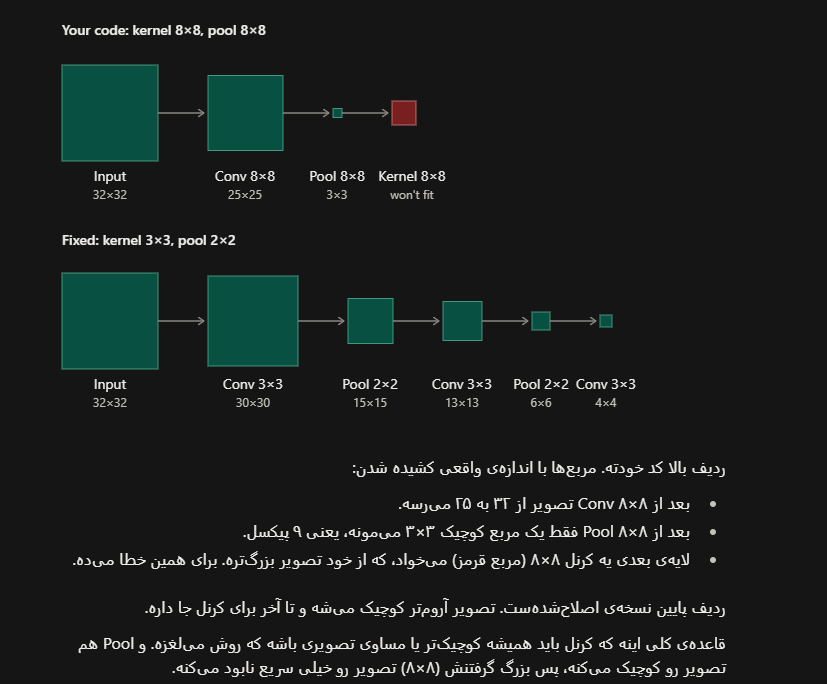

<div dir=rtl>
با این فرمول:

خروجی = ورودی − کرنل + 1

برای Conv ۸×۸ روی تصویر ۳۲×۳۲:

۳۲ − ۸ + ۱ = ۲۵

</div>

In [ ]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train = X_train / 255
X_test = X_test / 255

In [ ]:
X_train = X_train.reshape(-1,32,32,3)
X_test = X_test.reshape(-1,32,32,3)

In [ ]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

In [ ]:
model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(32, 32, 3)))
model.add(tf.keras.layers.Conv2D(8, (3, 3), activation="relu"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.MaxPool2D((2, 2))) # اندازه عکس رو نصف میکنه

model.add(tf.keras.layers.Conv2D(16, (3, 3), activation="relu"))
model.add(tf.keras.layers.MaxPool2D((2, 2)))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Conv2D(32, (3, 3), activation="relu"))

model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(64, activation="relu"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(128))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(256))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

In [ ]:
model.summary()

In [ ]:
model.compile(loss= tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) , optimizer='adam' , metrics= ['accuracy'])

In [ ]:
hist = model.fit(X_train,y_train,epochs=200,batch_size=64,validation_split=0.2)

In [ ]:
hist.history.keys()

In [ ]:
pt.plot(hist.history['accuracy'])
pt.plot(hist.history['loss'])

In [ ]:
pt.plot(hist.history['val_accuracy'])
pt.plot(hist.history['val_loss'])